# Step 5a — DistilBERT bi-encoder

Step 3's siamese model with DistilBERT as the encoder: each address encoded alone by one shared DistilBERT, masked mean pooling, head `[|u−v|; u⊙v]` → Linear → 1 logit.

Spec: `step5_spec.md`.

## 1. Setup

In [6]:
# Colab only (does nothing locally): mount Google Drive and work from the project's copy there.
# After this, every relative path (sys.path "..", load_pairs, CHECKPOINT_DIR = "checkpoints") points into Drive,
# so checkpoints survive a disconnect.
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/geocoding_ml/transformers")
    print("Colab: working in", os.getcwd())
except ImportError:
    pass

In [7]:
import sys
sys.path.append("..")   # geocoding_ml/ -> lets us import from helpers/
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from helpers.pairs import load_pairs
from torch.utils.data import DataLoader, Dataset, Subset
from esim.tokenizer import tokenize   # same tokenisation word2vec was trained with
from siamese_model.data_plumbing import PairDataset   # word-agnostic: returns raw strings
from torch import nn
import os, copy
from helpers.check_model_performance import review_typical_slices   # slice table used by evaluate
# only these four: real_training's own train_epoch / predict are Step 3's CPU versions
from siamese_model.real_training import is_better, broken_run_problems, THRESHOLD, CASE1_GUARDRAIL


DATASET = "overture_case2s"
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available()          # Colab GPU
                      else "mps" if torch.backends.mps.is_available()  # M1 Pro
                      else "cpu")
BATCH_SIZE = 32
CHECKPOINT_DIR = "checkpoints"   # git-ignored, relative to transformers/; on Colab point it at the Drive folder

train, train_label = load_pairs(DATASET, "train")
val, val_label = load_pairs(DATASET, "val")
test, test_label = load_pairs(DATASET, "test")
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
train.shape, val.shape, test.shape, DEVICE



UNK_ID = tok.unk_token_id
PAD_ID = tok.pad_token_id
vocab = tok.get_vocab()
SEEDS = [0, 1, 2]


## 2. Tokenise + collate

Each side tokenised alone (`[CLS] A [SEP]`), `padding=True`, `max_length=MAX_LENGTH`.

In [8]:
# encode_batch (from siamese_model/encode_batch_step.py, now at word level)
MAX_BATCH_FEATURE_SIZE = 64
def encode_batch(strings, vocab, max_len = MAX_BATCH_FEATURE_SIZE):
    strings = [["[CLS]"]+tok.tokenize(s)[:max_len] +["[SEP]"] for s in strings]
    batch_len = max([len(s) for s  in strings])
    ret = []
    for tokens in strings:
        res = [vocab.get(token, UNK_ID) for token in tokens]
        res += [PAD_ID] * (batch_len - len(res))
        ret.append(res)
    lengths = [len(s) for s  in strings]
    max_length = max(lengths)
    lengths_mask = (torch.arange(max_length)[None, :] < torch.tensor(lengths, dtype = torch.long).unsqueeze(-1)).long()


    return torch.tensor(ret, dtype = torch.long), lengths_mask


### Encode_Batch Checks
- Comparing results between our current encoder (`encode_batch`) and built-in `tok`
- Shape Matches, Ids Same, dtypes (both torch.long), matching masks, both start with `[CLS]`


In [9]:
# Test encode_batch against the Hugging Face tokenizer (known answer).
# Strings of different lengths, so padding is exercised; plus 50 real train addresses.
check_strings = ["4817 MAIN ST", "12 A", "PLEASANT VALLY RD APT 4B"] + train["address_b"].sample(50, random_state=0).tolist()

ids, mask = encode_batch(check_strings, vocab)
ref = tok(check_strings, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")

assert ids.shape == ref["input_ids"].shape, f"shape {tuple(ids.shape)} vs reference {tuple(ref['input_ids'].shape)} ([CLS]/[SEP] missing?)"
assert torch.equal(ids, ref["input_ids"]), "ids differ from the tokenizer's"
assert mask.dtype == torch.long, f"mask dtype {mask.dtype}, expected torch.long"
assert torch.equal(mask, ref["attention_mask"]), "mask differs (direction: 1 = real token, 0 = pad)"
assert (ids[:, 0] == tok.cls_token_id).all(), "first token is not [CLS]"
print("encode_batch matches the tokenizer:", tuple(ids.shape))
print(tok.decode(ids[0]), "|", mask[0].tolist())

encode_batch matches the tokenizer: (53, 13)
[CLS] 4817 main st [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] | [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]


In [10]:
def make_collate(vocab):
    def collate(samples):
        # samples = [(address_a, address_b, label), ...] -> encode each side separately
        addr_a, addr_b, labels = zip(*samples)
        ids_a, mask_a = encode_batch(list(addr_a), vocab)
        ids_b, mask_b = encode_batch(list(addr_b), vocab)
        y = torch.tensor(labels, dtype=torch.float32)
        return ids_a, mask_a, ids_b, mask_b, y
    return collate

train_dataset = PairDataset(train, train_label)
val_dataset = PairDataset(val, val_label)
test_dataset = PairDataset(test, test_label)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle = True, collate_fn = make_collate(vocab))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle = False, collate_fn= make_collate(vocab))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle = False, collate_fn= make_collate(vocab))

## 3. Encoder: DistilBERT + masked mean pooling

Tests directly under the class.

In [11]:
class MeanPooling(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, h, mask):
        # masked mean: zero the pad positions, divide by the true length
        return (h * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)   # (N, T, 768) -> (N, 768)


class BertEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = MeanPooling()
        self.bert = AutoModel.from_pretrained(MODEL_NAME)
        self.output_dim = self.bert.config.hidden_size

    def forward(self,ids, mask):
        bert_res = self.bert(input_ids=ids, attention_mask=mask)
        return self.pool(bert_res.last_hidden_state, mask)

#### Step 3 Tests
- Number of params ≈ 66.4 million (between 66M and 67M)
- Shape after `bert_encode` = (batch_size, 768)
- **A long address** in the batch adds pad columns to the short ones (sequence length T grows, batch size B doesn't)
- **Masked mean pooling** gives the same vectors with or without the extra pads; **naive mean pooling** (no mask) doesn't, which shows the test can catch a pad leak

In [12]:
bert_encode = BertEncoder()
# Test 0: parameter count (distilbert-base-uncased ≈ 66.4M; the pooling adds none)
n_params = sum(p.numel() for p in bert_encode.parameters())
assert 66e6 < n_params < 67e6, n_params
print("params:", n_params)

# Test 1: shape, on a small loader (8 train pairs, batch 4, real collate)
small_loader = DataLoader(Subset(train_dataset, range(8)), batch_size=4, shuffle=False, collate_fn=make_collate(vocab))
ids_a, mask_a, ids_b, mask_b, y = next(iter(small_loader))

bert_encode.eval()   # dropout off: same input -> same output
with torch.no_grad():
    v_a = bert_encode(ids_a, mask_a)
assert v_a.shape == (4, bert_encode.output_dim), v_a.shape
print("shape ok:", tuple(ids_a.shape), "->", tuple(v_a.shape))

# Test 3: pad invariance. The same two addresses, once in a short batch, once next to a much
# longer address (so they get many more [PAD]s). Masked mean -> the same vectors.
short = ["12 MAIN ST", "4817 ELM AVE"]
longer = short + ["THE SIMSBURY CEMETERY 16 HOPMEADOW STREET UNIT 4B BUILDING C NORTH ENTRANCE"]
ids_s, m_s = encode_batch(short, vocab)
ids_l, m_l = encode_batch(longer, vocab)
assert ids_l.shape[1] > ids_s.shape[1] + 5, "the long batch must actually add pads"

with torch.no_grad():
    v_s = bert_encode(ids_s, m_s)
    v_l = bert_encode(ids_l, m_l)[:2]
print("max |diff| masked mean:", (v_s - v_l).abs().max().item())
assert torch.allclose(v_s, v_l, atol=1e-5), "vectors change with padding -> pads leak into the mean"

# The test only counts if a broken version fails it: an unmasked mean (h.mean over T) must differ.
with torch.no_grad():
    h_s = bert_encode.bert(input_ids=ids_s, attention_mask=m_s).last_hidden_state
    h_l = bert_encode.bert(input_ids=ids_l, attention_mask=m_l).last_hidden_state[:2]
broken_gap = (h_s.mean(1) - h_l.mean(1)).abs().max().item()
print("max |diff| unmasked mean:", broken_gap)
assert broken_gap > 1e-3, "unmasked mean also passes -> the test can't tell the difference"
print("pad invariance ok")

params: 66362880
shape ok: (4, 8) -> (4, 768)
max |diff| masked mean: 8.046627044677734e-07
max |diff| unmasked mean: 1.3354523181915283
pad invariance ok


## 4. Bi-encoder: head + forward

Tests (incl. swap test: score(a, b) == score(b, a)) directly under the class.

In [13]:
class BiEncoder(nn.Module):
    """Pair of address ids -> one match logit. ONE encoder, called on both sides (weight sharing)."""
    def __init__(self):
        super().__init__()
        self.encoder = BertEncoder()
        self.head = nn.Linear(2 * self.encoder.output_dim, 1)

    def forward(self, ids_a, mask_a, ids_b, mask_b):
        a_out = self.encoder(ids_a, mask_a)                  # (B, T_a) -> (B, enc_dim)
        b_out = self.encoder(ids_b, mask_b)                  # same encoder: (B, T_b) -> (B, enc_dim)
        abs_diff = (a_out - b_out).abs()
        multiple = a_out * b_out
        combined = torch.cat([abs_diff, multiple], dim=1)   # both order-free -> score(a, b) == score(b, a); (B, 2 * enc_dim)
        res = self.head(combined)                           # (B, 1)
        return res.squeeze(-1)                              # logits (B,); no sigmoid: BCEWithLogitsLoss applies it

### Test BiEncoder
- Check size matches what we expect (4,)
- Check that order doesn't matter i.e **swapping** ids_a, ids_b doesn't have different result
    - Encountered a bug where even when we accidentally repeated `mask_b` twice, it still passed with swapped masks
    - **Why?** Because it was sampling on `positives:identical`, meaning `mask_a == mask_b`
    - **Solution:** make sure we're only sampling on `case3`. Also assert that sums for `mask_a/mask_b` pairs are all different

In [14]:
bi_encoder = BiEncoder().eval()

idx = np.flatnonzero(train["neg_type"].eq("case3").to_numpy())[:4]
small_loader = DataLoader(Subset(train_dataset, idx), batch_size=4, shuffle=False, collate_fn=make_collate(vocab))

ids_a, mask_a, ids_b, mask_b, y = next(iter(small_loader))
assert (mask_a.sum(1) != mask_b.sum(1)).any(), "Must pick rows where A and B differ in length"

res1 = bi_encoder(ids_a, mask_a, ids_b, mask_b)
assert res1.shape == (4,)
res2 = bi_encoder(ids_b, mask_b, ids_a, mask_a)
assert torch.allclose(res1, res2, atol=1e-5)

## 5. Optimiser + scheduler

AdamW, two groups: encoder 2e-5, head 1e-3; weight decay 0.01; 10% linear warm-up.

In [15]:
model = BiEncoder()
N_EPOCHS = 10
optimizer = torch.optim.AdamW([
    {"params": model.encoder.parameters(), "lr": 2e-5},
    {"params": model.head.parameters(),    "lr": 1e-3},
], weight_decay=0.01)

total_steps = len(train_loader) * N_EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)

- Shows the learning rate trajectory of Scheduler

/Users/david/Downloads/ml-geocoding/venv/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


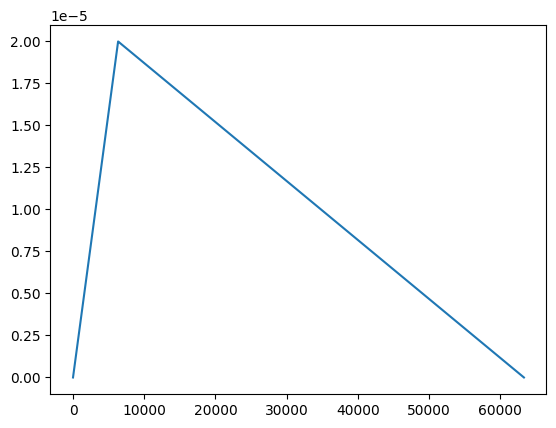

In [16]:
import matplotlib.pyplot as plt

opt_t = torch.optim.AdamW([torch.zeros(1, requires_grad=True)], lr=2e-5)
sch_t = get_linear_schedule_with_warmup(
    opt_t, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)

lrs = []
for _ in range(total_steps):
    lrs.append(sch_t.get_last_lr()[0]); sch_t.step()

plt.plot(lrs)

## 6. Timing: one epoch on a 10k train slice

Batch 32, on `DEVICE`. Decides epoch budget and M1 Pro vs Colab.

In [17]:
def to_device(batch):
    return (t.to(DEVICE) for t in batch)                             # all five tensors: ids_a, mask_a, ids_b, mask_b, y

def sync():
    # GPUs run asynchronously: wait until the queued work is done before reading the clock
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()

def train_epoch(model, loader, opt, sched, loss_fn):
    model.train()
    total_loss, n_pairs = 0.0, 0
    for batch in loader:
        ids_a, mask_a, ids_b, mask_b, y = to_device(batch)
        opt.zero_grad()                                              # first: clear anything left from before
        logits = model(ids_a, mask_a, ids_b, mask_b)                 # the model never sees y
        loss = loss_fn(logits, y)                                    # BCEWithLogitsLoss applies the sigmoid itself
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)   # between backward and step: edits the gradients step uses
        opt.step()
        sched.step()                                                 # after opt.step(): sets the lr for the next batch
        total_loss += loss.item() * len(y)                           # weight by batch size -> average per pair, not per batch
        n_pairs += len(y)
    return total_loss / n_pairs

def predict(model, loader):
    model.eval()
    probs = []
    with torch.no_grad():                                            # no graph recorded, no updates
        for batch in loader:
            ids_a, mask_a, ids_b, mask_b, y = to_device(batch)       # y unused
            logits = model(ids_a, mask_a, ids_b, mask_b)
            probs.append(torch.sigmoid(logits).cpu())                # logits -> probabilities, back on the CPU
    return torch.cat(probs)                                          # (N,), in loader order: val/test loaders must not shuffle

In [18]:
import time
SEED = 0
N_TIMING_BATCHES = 200

torch.manual_seed(SEED)
timing_model = BiEncoder().to(DEVICE)
timing_opt = torch.optim.AdamW([
    {"params": timing_model.encoder.parameters(), "lr": 2e-5},
    {"params": timing_model.head.parameters(),    "lr": 1e-3},
], weight_decay=0.01)
timing_steps = N_TIMING_BATCHES  # one pass over the timing slice
timing_sched = get_linear_schedule_with_warmup(
    timing_opt, num_warmup_steps=int(0.1 * timing_steps), num_training_steps=timing_steps)

# random rows: the first train rows are short identical positives and would understate the time
rng = np.random.default_rng(SEED)
timing_idx = rng.choice(len(train_dataset), N_TIMING_BATCHES * BATCH_SIZE, replace=False)
subset_loader = DataLoader(Subset(train_dataset, timing_idx), batch_size=BATCH_SIZE, collate_fn=make_collate(vocab))

# train/val loaders come from §2 (train shuffled); don't rebuild them here

t0 = time.perf_counter()
train_epoch(timing_model, subset_loader, timing_opt, timing_sched, nn.BCEWithLogitsLoss())
sync()
train_seconds = time.perf_counter() - t0
print(f"train: {train_seconds / N_TIMING_BATCHES:.3f} s/batch -> {train_seconds / N_TIMING_BATCHES * len(train_loader) / 60:.1f} min/epoch")

t0 = time.perf_counter()
predict(timing_model, val_loader)
sync()
print(f"val pass: {time.perf_counter() - t0:.1f} s")

del timing_model, timing_opt, timing_sched
torch.mps.empty_cache()

KeyboardInterrupt: 

## 7. Training

Best epoch = highest val non-identical found with val case1 ≥ 98%.

In [19]:
def evaluate(model, loader, df, labels):
    """Copied from siamese_model/real_training.py; calls this notebook's device-aware predict."""
    probs = predict(model, loader)
    y_true = torch.tensor(labels.values, dtype=torch.float32)
    preds = (probs >= THRESHOLD).int().numpy()
    val_loss = nn.functional.binary_cross_entropy(probs, y_true).item()
    table = review_typical_slices(df, preds, labels).set_index("slice")
    pct = lambda name: float(100 * table.loc[name, "correct"] / table.loc[name, "n"])
    found = pct("positives: non-identical")
    case1 = pct("neg: case1 (same street, diff number)")
    easy = pct("neg: case3 (easy)")
    return {"val_loss": val_loss, "found": found, "case1": case1, "easy": easy}


MAX_EPOCHS = 5
PATIENCE = 2


def run_training(seed, train_loader=train_loader, checkpoint_dir=CHECKPOINT_DIR, max_epochs=MAX_EPOCHS):
    # train_loader / checkpoint_dir / max_epochs are arguments so the dry run can't leave a global changed
    torch.manual_seed(seed)
    last_path = f"{checkpoint_dir}/seed_{seed}_last.pt"
    final_path = f"{checkpoint_dir}/seed_{seed}_final.pt"

    model = BiEncoder().to(DEVICE)
    model.train()
    opt = torch.optim.AdamW([
        {"params": model.encoder.parameters(), "lr": 2e-5},
        {"params": model.head.parameters(),    "lr": 1e-3},
    ], weight_decay=0.01)
    total_steps = len(train_loader) * max_epochs
    sched = get_linear_schedule_with_warmup(
        opt, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)
    loss_fn = nn.BCEWithLogitsLoss()

    best, best_state, history = None, None, []
    epochs_since_best, start_epoch = 0, 0
    
    if os.path.exists(last_path):                      # a disconnected run: continue after its last finished epoch
        ck = torch.load(last_path, map_location=DEVICE)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        history, best, best_state, epochs_since_best = ck["history"], ck["best"], ck["best_state"], ck["epochs_since_best"]
        start_epoch = ck["epoch"] + 1
        print(f"seed {seed}: resuming at epoch {start_epoch}")
    
    for epoch in range(start_epoch, max_epochs):
        train_loss = train_epoch(model, train_loader, opt,sched, loss_fn)
        
        row = {"epoch": epoch, "train_loss": train_loss,"lr_encoder": sched.get_last_lr()[0], **evaluate(model, val_loader, val, val_label)}
        print(row)
        history.append(row)

        

        if is_better(row, best):
            best, best_state, epochs_since_best = row, copy.deepcopy(model.state_dict()), 0
        else:
            epochs_since_best += 1
            if epochs_since_best >= PATIENCE:
                break

        state = {
            "epoch": epoch, "model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), 
            "history": history, "best": best,
            "best_state": best_state, "epochs_since_best": epochs_since_best,
        }
        torch.save(state, last_path + ".tmp")
        os.replace(last_path + ".tmp", last_path)
        
    # no epoch reached the case1 guardrail -> keep the last epoch's weights
    if best is None:
        best_state = copy.deepcopy(model.state_dict())
    
    torch.save({"seed": seed, "best_state": best_state, "best": best, "history": history}, final_path)
    return pd.DataFrame(history), best, best_state

In [ ]:
# Dry run: 64 rows (2 batches), 2 epochs, its own folder. Check, in order:
#  1. run it, interrupt during epoch 1's val pass (after epoch 0's row printed) -> checkpoints_dry/seed_0_last.pt exists
#  2. run it again -> prints "seed 0: resuming at epoch 1", finishes, writes seed_0_final.pt
#  3. then delete checkpoints_dry/ (the queue below never reads it)
dry_loader = DataLoader(Subset(train_dataset, range(64)), batch_size=BATCH_SIZE, shuffle=True, collate_fn=make_collate(vocab))
os.makedirs("checkpoints_dry", exist_ok=True)
dry_history, dry_best, _ = run_training(0, train_loader=dry_loader, checkpoint_dir="checkpoints_dry", max_epochs=2)
dry_history

In [ ]:
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
for seed in SEEDS:
    if os.path.exists(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt"):
        print(f"seed {seed}: already finished, skipping")
        continue
    history, best, best_state = run_training(seed)
    print(seed, broken_run_problems(history))

NameError: name 'os' is not defined

## 8. Results

Slice table on val, then test; rare-number case1 group.

In [ ]:
# Run health + best epoch per seed (run by Claude 2026-11-11 at David's request).
# Pass: problems == [] and best epoch < MAX_EPOCHS - 1 (else 5 epochs was too few).
for seed in SEEDS:
    ck = torch.load(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt", map_location="cpu", weights_only=False)
    h = pd.DataFrame(ck["history"])
    print(f"--- seed {seed}: problems {broken_run_problems(h)}, best epoch {ck['best']['epoch']}, epochs run {len(h)}")
    display(h.round(4))


--- seed 0: problems [], best epoch 4, epochs run 5


,epoch,train_loss,lr_encoder,val_loss,found,case1,easy
0,0,0.0659,0.0,0.0535,80.9285,99.5356,99.9869
1,1,0.0275,0.0,0.0489,81.3049,99.8912,99.9956
2,2,0.0180,0.0,0.0493,82.8105,99.7025,99.9826
3,3,0.0118,0.0,0.0579,84.5671,99.5066,99.9782
4,4,0.0067,0.0,0.0633,85.9473,99.3614,99.9739


--- seed 1: problems [], best epoch 4, epochs run 5


,epoch,train_loss,lr_encoder,val_loss,found,case1,easy
0,0,0.0667,0.0,0.0666,83.1870,99.1655,99.9739
1,1,0.0288,0.0,0.0472,81.8068,99.8041,99.9695
2,2,0.0139,0.0,0.0655,84.8181,99.2816,99.9782
3,3,0.0050,0.0,0.0716,85.3199,99.3760,99.9739
4,4,0.0081,0.0,0.0843,85.8218,99.2961,99.9826


--- seed 2: problems [], best epoch 1, epochs run 4


,epoch,train_loss,lr_encoder,val_loss,found,case1,easy
0,0,0.0657,0.0,0.0532,80.3011,99.7823,99.9913
1,1,0.0286,0.0,0.0546,87.2020,98.9333,99.9652
2,2,0.0183,0.0,0.0582,85.9473,99.1655,99.9695
3,3,0.0087,0.0,0.0680,84.9435,99.5138,99.9869


In [20]:
import itertools

splits = {"val": (val_loader, val, val_label), "test": (test_loader, test, test_label)}

for seed, phase in itertools.product(SEEDS, splits):
    loader, df, labels = splits[phase]
    output_path = os.path.join(CHECKPOINT_DIR, f"preds_{phase}_seed_{seed}.npy")   # name esim_diagnostics reads
    checkpoint_path = os.path.join(CHECKPOINT_DIR, f"seed_{seed}_final.pt")
    assert os.path.exists(checkpoint_path)
    if os.path.exists(output_path):          # written once; a re-run never recomputes
        continue

    model = BiEncoder().to(DEVICE)
    ck = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)   # saved on Colab's GPU
    model.load_state_dict(ck["best_state"])

    with torch.no_grad():
        preds = (predict(model, loader) >= THRESHOLD).int().numpy()
    np.save(output_path, preds)
    print(seed, phase)
    display(review_typical_slices(df, preds, labels))


0 val


,slice,n,correct,errors,% correct
0,positives: identical,3390,3390,0,100.0%
1,positives: non-identical,797,685,112,85.9%
2,"neg: case1 (same street, diff number)",13781,13693,88,99.4%
3,"neg: case2 (same number, similar street)",34,16,18,47.1%
4,neg: case3 (easy),22969,22963,6,100.0%
5,neg: case2s (swapped look-alike street),894,556,338,62.2%
6,overall (accuracy),41865,41303,562,98.7%


0 test


,slice,n,correct,errors,% correct
0,positives: identical,3543,3543,0,100.0%
1,positives: non-identical,843,691,152,82.0%
2,"neg: case1 (same street, diff number)",14448,14367,81,99.4%
3,"neg: case2 (same number, similar street)",15,7,8,46.7%
4,neg: case3 (easy),23942,23931,11,100.0%
5,neg: case2s (swapped look-alike street),1053,662,391,62.9%
6,overall (accuracy),43844,43201,643,98.5%


1 val


,slice,n,correct,errors,% correct
0,positives: identical,3390,3390,0,100.0%
1,positives: non-identical,797,684,113,85.8%
2,"neg: case1 (same street, diff number)",13781,13684,97,99.3%
3,"neg: case2 (same number, similar street)",34,17,17,50.0%
4,neg: case3 (easy),22969,22965,4,100.0%
5,neg: case2s (swapped look-alike street),894,532,362,59.5%
6,overall (accuracy),41865,41272,593,98.6%


... (2 outputs left out)

2 val


,slice,n,correct,errors,% correct
0,positives: identical,3390,3390,0,100.0%
1,positives: non-identical,797,695,102,87.2%
2,"neg: case1 (same street, diff number)",13781,13634,147,98.9%
3,"neg: case2 (same number, similar street)",34,16,18,47.1%
4,neg: case3 (easy),22969,22961,8,100.0%
5,neg: case2s (swapped look-alike street),894,554,340,62.0%
6,overall (accuracy),41865,41250,615,98.5%


2 test


,slice,n,correct,errors,% correct
0,positives: identical,3543,3543,0,100.0%
1,positives: non-identical,843,706,137,83.7%
2,"neg: case1 (same street, diff number)",14448,14307,141,99.0%
3,"neg: case2 (same number, similar street)",15,4,11,26.7%
4,neg: case3 (easy),23942,23929,13,99.9%
5,neg: case2s (swapped look-alike street),1053,649,404,61.6%
6,overall (accuracy),43844,43138,706,98.4%


In [22]:
# Comparison with ESIM's chosen setting, same pairs, same slice code (run by Claude 2026-11-11 at David's request).
# Other models' case2s rows: results.md, "Overture case2s" table.
from esim.esim_diagnostics import slice_table, rare_number_table
S = {"5a": CHECKPOINT_DIR, "rand_mc2": "../esim/checkpoints/esim_rand_mc2"}
for name, (df, labels) in {"val": (val, val_label), "test": (test, test_label)}.items():
    print(name)
    display(slice_table(df, labels, name, settings=S))
display(rare_number_table({"val": (val, val_label), "test": (test, test_label)}, settings=S,
                          w2v_path="../esim/checkpoints/word2vec_50_mc2.model"))


val


5a                 rand_mc2  \
                                               0       1       2        0   
slice                                                                       
positives: identical                      100.0%  100.0%  100.0%   100.0%   
positives: non-identical                   85.9%   85.8%   87.2%    77.8%   
neg: case1 (same street, diff number)      99.4%   99.3%   98.9%    99.0%   
neg: case2 (same number, similar street)   47.1%   50.0%   47.1%    55.9%   
neg: case3 (easy)                         100.0%  100.0%  100.0%   100.0%   
neg: case2s (swapped look-alike street)    62.2%   59.5%   62.0%    74.6%   
overall (accuracy)                         98.7%   98.6%   98.5%    98.7%   

                                                          
                                               1       2  
slice                                                     
positives: identical                      100.0%  100.0%  
positives: non-identical                   81.8%   80.3%  
neg: case1 (same street, diff number)      99.0%   99.2%  
neg: case2 (same number, similar street)   55.9%   55.9%  
neg: case3 (easy)                         100.0%  100.0%  
neg: case2s (swapped look-alike street)    76.0%   82.2%  
overall (accuracy)                         98.8%   98.9%

test


5a                 rand_mc2  \
                                               0       1       2        0   
slice                                                                       
positives: identical                      100.0%  100.0%  100.0%    99.9%   
positives: non-identical                   82.0%   83.0%   83.7%    74.9%   
neg: case1 (same street, diff number)      99.4%   99.3%   99.0%    98.9%   
neg: case2 (same number, similar street)   46.7%   66.7%   26.7%    33.3%   
neg: case3 (easy)                         100.0%  100.0%   99.9%   100.0%   
neg: case2s (swapped look-alike street)    62.9%   58.2%   61.6%    72.9%   
overall (accuracy)                         98.5%   98.4%   98.4%    98.4%   

                                                         
                                               1      2  
slice                                                    
positives: identical                      100.0%  99.9%  
positives: non-identical                   78.9%  78.2%  
neg: case1 (same street, diff number)      98.9%  98.6%  
neg: case2 (same number, similar street)   26.7%  46.7%  
neg: case3 (easy)                          99.9%  99.9%  
neg: case2s (swapped look-alike street)    75.9%  74.1%  
overall (accuracy)                         98.6%  98.4%

identical UNK: found case1 UNK: rejected  \
split setting  seed                                            
val   5a       0                 78 / 78           160 / 161   
               1                 78 / 78           158 / 161   
               2                 78 / 78           156 / 161   
      rand_mc2 0                 78 / 78           158 / 161   
               1                 78 / 78           155 / 161   
               2                 78 / 78           154 / 161   
test  5a       0               178 / 178           404 / 404   
               1               178 / 178           403 / 404   
               2               178 / 178           403 / 404   
      rand_mc2 0               178 / 178           385 / 404   
               1               178 / 178           392 / 404   
               2               178 / 178           379 / 404   

                     identical other: missed  case1 other: errors  
split setting  seed                                                
val   5a       0                           0                   87  
               1                           0                   94  
               2                           0                  142  
      rand_mc2 0                           0                  128  
               1                           0                  132  
               2                           0                  100  
test  5a       0                           0                   81  
               1                           0                   97  
               2                           0                  140  
      rand_mc2 0                           3                  143  
               1                           0                  152  
               2                           2                  171

## Diagnostics

One-off queries and their results (question → result → query).

**D1 (Claude, 2026-11-11, at David's request): are the saved predictions the right ones?** Question: did inference load each seed's best weights and score the right split? Check: val predictions recomputed through `review_typical_slices` must reproduce the `found` / `case1` stored in `final.pt`'s `best` row exactly; every file has its split's row count. Result: all three seeds reproduce exactly (seed 0: 85.9473 / 99.3614, seed 1: 85.8218 / 99.2961, seed 2: 87.2020 / 98.9333); val 41,865 and test 43,844 rows. Query below.


In [ ]:
for seed in SEEDS:
    best = torch.load(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt", map_location="cpu", weights_only=False)["best"]
    for split, (df, labels) in {"val": (val, val_label), "test": (test, test_label)}.items():
        p = np.load(f"{CHECKPOINT_DIR}/preds_{split}_seed_{seed}.npy")
        assert len(p) == len(df)
        t = review_typical_slices(df, p, labels).set_index("slice")
        pct = lambda n: float(100 * t.loc[n, "correct"] / t.loc[n, "n"])
        found, case1 = pct("positives: non-identical"), pct("neg: case1 (same street, diff number)")
        if split == "val":
            assert abs(found - best["found"]) < 1e-9 and abs(case1 - best["case1"]) < 1e-9, (seed, found, best)
    print(f"seed {seed}: val matches the training history")


**D2 (Claude, 2026-11-11, at David's request): is 5a's low `case2s` rejection a threshold effect or a ranking failure?** Val probabilities saved as `probs_val_seed_{s}.npy` (same `predict`, no threshold; `>= 0.5` reproduces the saved predictions). AUC of non-identical positives (797) vs `case2s` negatives (894): **0.867 / 0.857 / 0.868**. Moving the threshold until 75% of `case2s` is rejected (ESIM / siamese level) needs 0.92–0.99, and found then drops to **79.8–80.3** (case1 rejected 99.8–99.9). Diagnostic only: the threshold is set on the same val rows, so it is optimistic and not a reportable number. Query below.


In [ ]:
from sklearn.metrics import roc_auc_score
pos = (val_label.values == 1) & (val["address_a"] != val["address_b"]).values
c2s = (val["neg_type"] == "case2s").values
case1 = (val["neg_type"] == "case1").values
for seed in SEEDS:
    path = f"{CHECKPOINT_DIR}/probs_val_seed_{seed}.npy"
    if not os.path.exists(path):   # same model load as the prediction loop, probabilities kept
        model = BiEncoder().to(DEVICE)
        model.load_state_dict(torch.load(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt", map_location=DEVICE, weights_only=False)["best_state"])
        np.save(path, predict(model, val_loader).numpy())
    p = np.load(path)
    auc = roc_auc_score(np.r_[np.ones(pos.sum()), np.zeros(c2s.sum())], np.r_[p[pos], p[c2s]])
    t = np.quantile(p[c2s], 0.75)   # threshold that rejects 75% of case2s
    print(f"seed {seed}: AUC {auc:.3f} | thr {t:.3f} -> found {100*(p[pos] >= t).mean():.1f}, case1 rejected {100*(p[case1] < t).mean():.1f}")


**D3 (Claude, 2026-11-11, at David's request): the same check for ESIM `rand_mc2`.** Val probabilities saved as `../esim/checkpoints/esim_rand_mc2/probs_val_seed_{s}.npy` (`>= 0.5` reproduces ESIM's saved predictions). AUC non-identical vs `case2s`: **0.856 / 0.862 / 0.878** (5a: 0.857 / 0.857–0.868). At 75% `case2s` rejected: found **77.5 / 82.7 / 83.1** (5a: 79.8–80.3), case1 rejected 98.7–99.1. ESIM's 0.5 already sits near that point (thresholds 0.27–0.51); 5a's does not (0.92–0.99). Same caveat as D2: val-tuned, diagnostic only. Query (run from `esim/` in the run; here with paths from `transformers/`):


In [ ]:
import pandas as pd
from siamese_model.training_step import predict as esim_predict   # Step 3's CPU predict, as ESIM used
from esim.esim_model import ESIM, make_loaders, random_rows_table
ESIM_DIR = "../esim/checkpoints/esim_rand_mc2"
all_addr = pd.concat([d[c] for d in (train, val, test) for c in ("address_a", "address_b")])
esim_vocab, esim_matrix, _ = random_rows_table(all_addr, min_count=2, seed=0)   # rand_mc2's table
esim_loader = make_loaders(esim_vocab, {"val": (val, val_label)})["val"]
for seed in SEEDS:
    path = f"{ESIM_DIR}/probs_val_seed_{seed}.npy"
    if not os.path.exists(path):
        m = ESIM(esim_matrix)
        m.load_state_dict(torch.load(f"{ESIM_DIR}/esim_seed_{seed}.pt", weights_only=False)["state_dict"])
        np.save(path, esim_predict(m, esim_loader).numpy())
    p = np.load(path)
    auc = roc_auc_score(np.r_[np.ones(pos.sum()), np.zeros(c2s.sum())], np.r_[p[pos], p[c2s]])
    t = np.quantile(p[c2s], 0.75)
    print(f"ESIM seed {seed}: AUC {auc:.3f} | thr {t:.3f} -> found {100*(p[pos] >= t).mean():.1f}, case1 rejected {100*(p[case1] < t).mean():.1f}")


**D4 (Claude, 2026-11-11, at David's request): do D2/D3 hold on test?** Test probabilities saved for both models (`probs_test_seed_{s}.npy`; `>= 0.5` reproduces the saved test predictions). Each seed's val threshold (75% `case2s` rejected on val) frozen and applied once to test. **AUC (threshold-free) — 5a 0.836 / 0.840 / 0.845, ESIM 0.815 / 0.837 / 0.842.** At the frozen thresholds — 5a: found 75.0 / 75.2 / 76.4, `case2s` rejected 74.5 / 80.2 / 78.1, case1 99.8–99.9; ESIM: found 74.9 / 79.6 / 84.2, `case2s` rejected 72.9 / 75.4 / 64.7, case1 98.0–98.9. Identical and easy unchanged (≥ 99.9). Query below.


In [ ]:
def slice_masks(df, labels):
    return {"pos": (labels.values == 1) & (df["address_a"] != df["address_b"]).values,
            "c2s": (df["neg_type"] == "case2s").values, "case1": (df["neg_type"] == "case1").values}
mv, mt = slice_masks(val, val_label), slice_masks(test, test_label)
for name, folder in {"5a": CHECKPOINT_DIR, "ESIM rand_mc2": ESIM_DIR}.items():
    for seed in SEEDS:
        pv, pt = np.load(f"{folder}/probs_val_seed_{seed}.npy"), np.load(f"{folder}/probs_test_seed_{seed}.npy")
        t = np.quantile(pv[mv["c2s"]], 0.75)   # frozen from val
        auc = roc_auc_score(np.r_[np.ones(mt["pos"].sum()), np.zeros(mt["c2s"].sum())], np.r_[pt[mt["pos"]], pt[mt["c2s"]]])
        print(f"{name} seed {seed}: test AUC {auc:.3f} | thr {t:.3f} -> found {100*(pt[mt['pos']] >= t).mean():.1f}, "
              f"case2s rejected {100*(pt[mt['c2s']] < t).mean():.1f}, case1 rejected {100*(pt[mt['case1']] < t).mean():.1f}")
